In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# print(os.getcwd())
# print(os.path.abspath(base_path))


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

In [2]:
# ls

In [3]:
base_path = "../results_general_proportion"

folders = {

    3: "mmlu_test_eval_service_3_prop",
    5: "mmlu_test_eval_service_5_prop",
    8: "mmlu_test_eval_service_8_prop",
    10: "mmlu_test_eval_service_10_prop",
    12: "mmlu_test_eval_service_12_prop",
    14: "mmlu_test_eval_service_14_prop"

}

In [4]:
data = {}

for k, folder_name in folders.items():

    folder_path = os.path.join(base_path, folder_name)
#     print(folder_path)

    data[k] = []

    for file_name in os.listdir(folder_path):

        if not file_name.endswith(".json"):
            continue

        if "_efficiency" in file_name:
            continue

        file_path = os.path.join(folder_path, file_name)
#         print(file_path)

        with open(file_path, "r") as f:
            rows = json.load(f)
#             print(rows)

        for row in rows:
            row = row.copy()
            row["source_file"] = file_name
            data[k].append(row)

    print(f"K={k}: loaded {len(data[k])} rows")

K=3: loaded 6300 rows
K=5: loaded 10500 rows
K=8: loaded 16800 rows
K=10: loaded 21000 rows
K=12: loaded 25200 rows
K=14: loaded 29400 rows


In [5]:
df_k3 = pd.DataFrame(data[3])
df_k5 = pd.DataFrame(data[5])
df_k8 = pd.DataFrame(data[8])
df_k10 = pd.DataFrame(data[10])
df_k12 = pd.DataFrame(data[12])
df_k14 = pd.DataFrame(data[14])


print("K=3:", df_k3.shape)
print("K=5:", df_k5.shape)
print("K=8:", df_k8.shape)
print("K=10:", df_k10.shape)
print("K=12:", df_k12.shape)
print("K=14:", df_k14.shape)

K=3: (6300, 31)
K=5: (10500, 33)
K=8: (16800, 36)
K=10: (21000, 38)
K=12: (25200, 40)
K=14: (29400, 42)


In [6]:
# df_k3.columns.tolist()# df_k3.columns

### combined df

In [7]:
df_combined = pd.concat([df_k3, df_k5, df_k8, df_k10, df_k12, df_k14], ignore_index=True)

print(df_combined.shape)
print(df_combined["total_service_count"].value_counts())
# df_combined.columns

(109200, 42)
14    29400
12    25200
10    21000
8     16800
5     10500
3      6300
Name: total_service_count, dtype: int64


In [8]:
general = df_combined[df_combined["expected_service"]=="general"]

In [9]:
general.head()

,routing_method,query,raw_response,predicted_label,top_candidate,model_name,latency_ms,max_score,median_score,abstract_algebra_score,anatomy_score,astronomy_score,apply_threshold,gate,gap,gap_cutoff,gap_passed,margin,margin_cutoff,margin_passed,zscore,gate_value,gate_cutoff,gate_passed,expected_service,is_correct,error,energy_kwh,co2_kg,total_service_count,source_file,business_ethics_score,college_computer_science_score,high_school_chemistry_score,high_school_geography_score,jurisprudence_score,world_religions_score,formal_logic_score,marketing_score,sociology_score,high_school_psychology_score,prehistory_score
300,bi-encoder,app does not recognize me,None,general,anatomy,Qwen/Qwen3-Embedding-0.6B,29.084780,0.212174,0.199686,0.150618,0.212174,0.199686,True,gap,0.012488,0.105003,False,0.012488,None,None,0.928987,0.012488,0.105003,False,general,True,None,9.510000e-08,5.220000e-08,3,bi-encoder_Qwen-Qwen3-Embedding-0.6B.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
301,bi-encoder,what battery percentage is my phone at,None,general,anatomy,Qwen/Qwen3-Embedding-0.6B,28.891185,0.194721,0.140454,0.140454,0.194721,0.137146,True,gap,0.054267,0.105003,False,0.054267,None,None,1.412361,0.054267,0.105003,False,general,True,None,2.973900e-06,1.631800e-06,3,bi-encoder_Qwen-Qwen3-Embedding-0.6B.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
302,bi-encoder,How long will it take for my transaction to be completed?,None,general,astronomy,Qwen/Qwen3-Embedding-0.6B,28.999577,0.185246,0.164337,0.103289,0.164337,0.185246,True,gap,0.020909,0.105003,False,0.020909,None,None,0.986140,0.020909,0.105003,False,general,True,None,9.570000e-08,5.250000e-08,3,bi-encoder_Qwen-Qwen3-Embedding-0.6B.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
303,bi-encoder,i would like to know the status of my credit card application,None,general,anatomy,Qwen/Qwen3-Embedding-0.6B,29.046149,0.310398,0.209188,0.161260,0.310398,0.209188,True,gap,0.101210,0.105003,False,0.101210,None,None,1.342339,0.101210,0.105003,False,general,True,None,2.946300e-06,1.616600e-06,3,bi-encoder_Qwen-Qwen3-Embedding-0.6B.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
304,bi-encoder,Why is my payment pending?,None,general,anatomy,Qwen/Qwen3-Embedding-0.6B,28.955020,0.217284,0.182860,0.108056,0.217284,0.182860,True,gap,0.034424,0.105003,False,0.034424,None,None,1.050168,0.034424,0.105003,False,general,True,None,2.459300e-06,1.349400e-06,3,bi-encoder_Qwen-Qwen3-Embedding-0.6B.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
import matplotlib.pyplot as plt

for model, df_model in general.groupby("model_name"):

    plt.figure(figsize=(8, 5))

    plt.plot(
        df_model["total_service_count"],
        df_model["max_score"].mean(),
        marker="o",
        linewidth=2,
        label="Mean Max Score"
    )

    plt.plot(
        df_model["total_service_count"],
        df_model["median_score"].mean(),
        marker="s",
        linestyle="--",
        linewidth=2,
        label="Mean Median Score"
    )

    plt.xlabel("Pool Size (K)")
    plt.ylabel("Score")
    plt.title(model)
    plt.xticks(sorted(df_model["total_service_count"].unique()))
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

KeyError: 'mean_max_score'

<Figure size 800x500 with 0 Axes>

In [49]:
gap_stats = (
    general
    .groupby(["model_name", "total_service_count"])["gap"]
    .mean()
    .reset_index(name="mean_gap")
    .sort_values(["model_name", "total_service_count"])
)

print(gap_stats)

                                model_name  total_service_count   mean_gap
0                   BAAI/bge-large-en-v1.5                    3 0.02982169
1                   BAAI/bge-large-en-v1.5                    5 0.03917054
2                   BAAI/bge-large-en-v1.5                    8 0.05334794
3                   BAAI/bge-large-en-v1.5                   10 0.05779302
4                   BAAI/bge-large-en-v1.5                   12 0.07073367
5                   BAAI/bge-large-en-v1.5                   14 0.07538001
6                  BAAI/bge-reranker-v2-m3                    3 0.00001464
7                  BAAI/bge-reranker-v2-m3                    5 0.00003452
8                  BAAI/bge-reranker-v2-m3                    8 0.00003500
9                  BAAI/bge-reranker-v2-m3                   10 0.00005181
10                 BAAI/bge-reranker-v2-m3                   12 0.00007468
11                 BAAI/bge-reranker-v2-m3                   14 0.00003403
12              LiquidAI/

In [56]:
general_stats["max_minus_median"] = (
    general_stats["mean_max_score"]
    - general_stats["mean_median_score"]
)

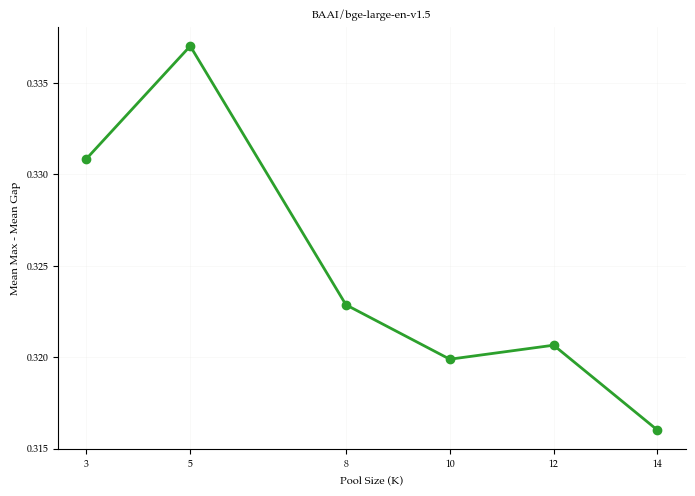

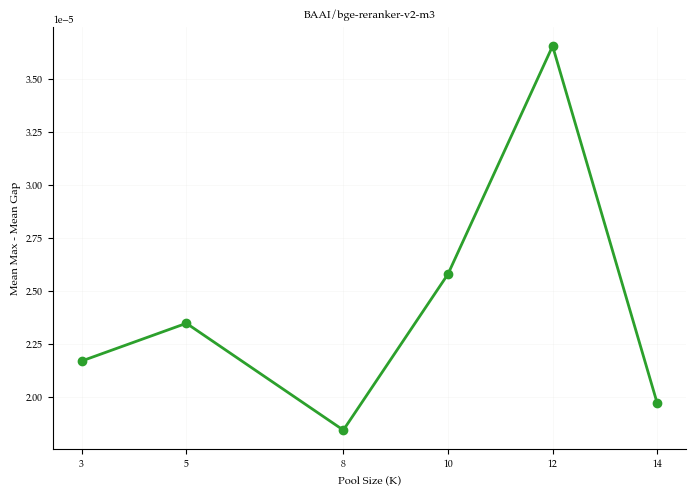

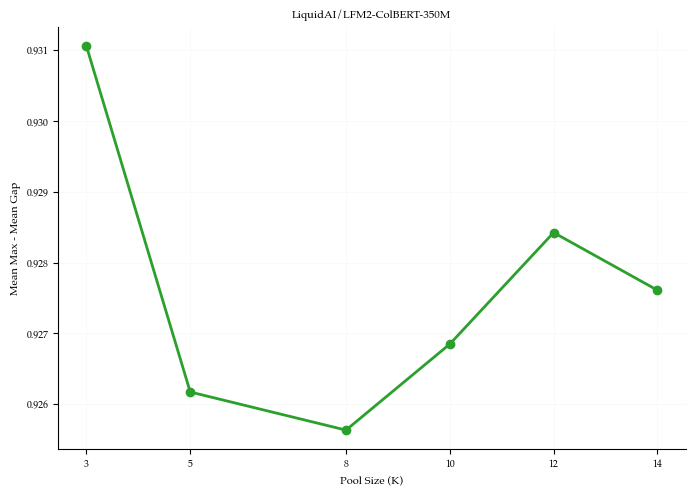

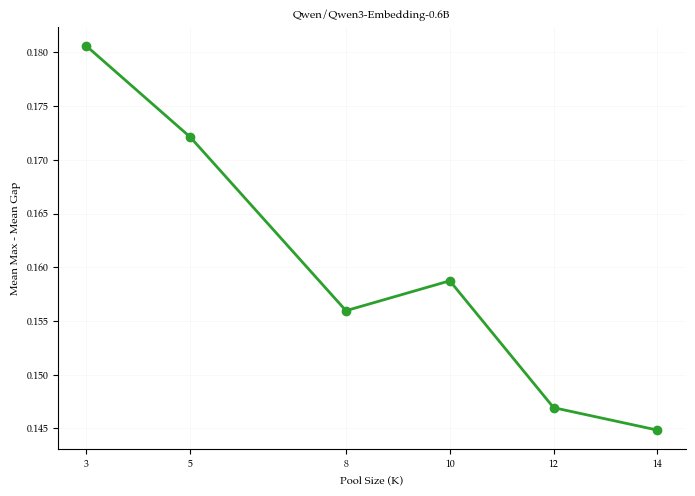

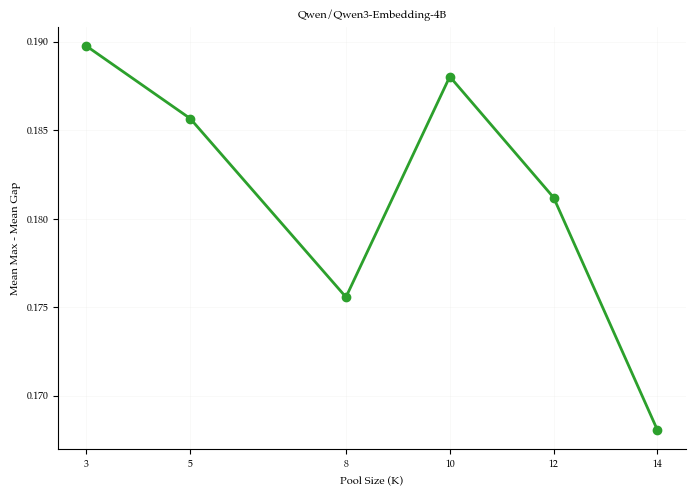

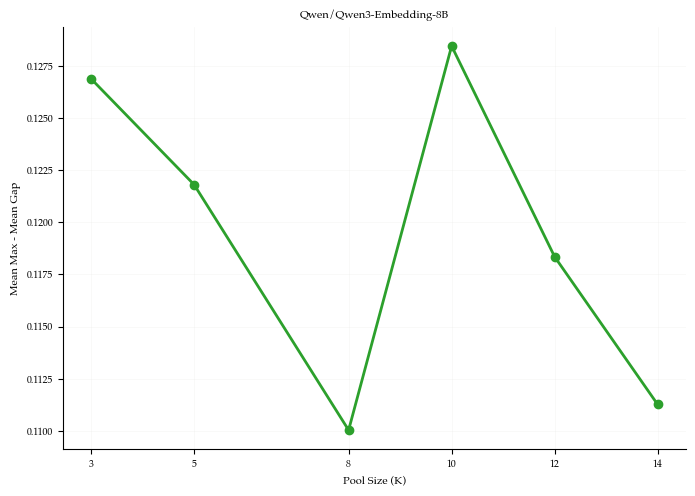

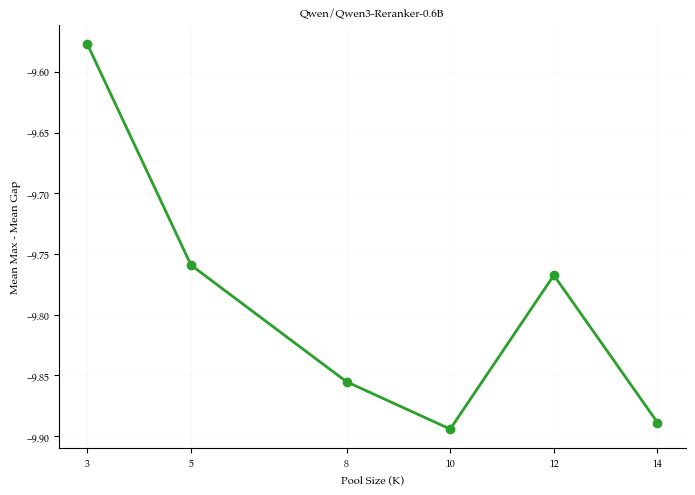

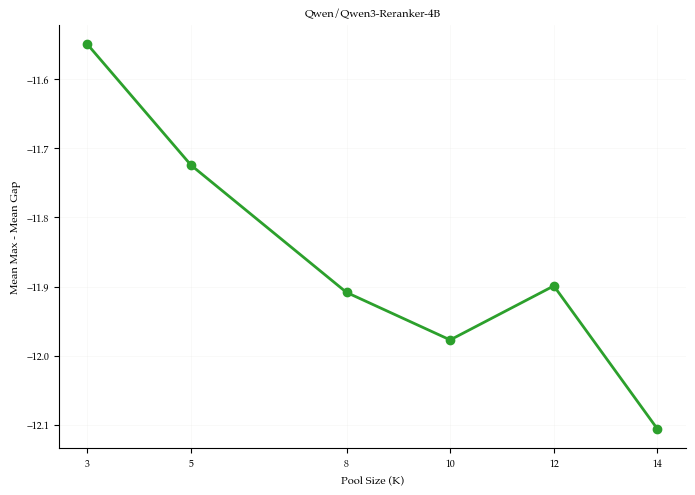

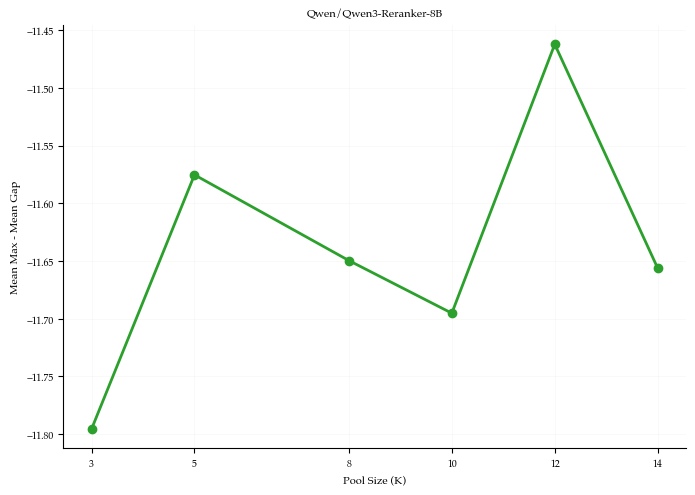

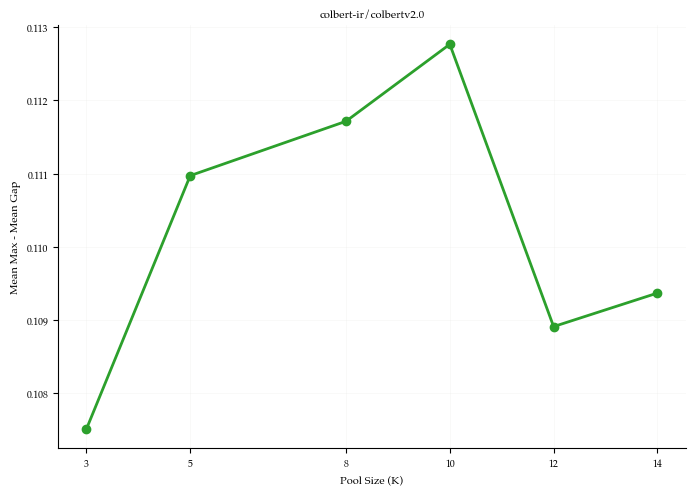

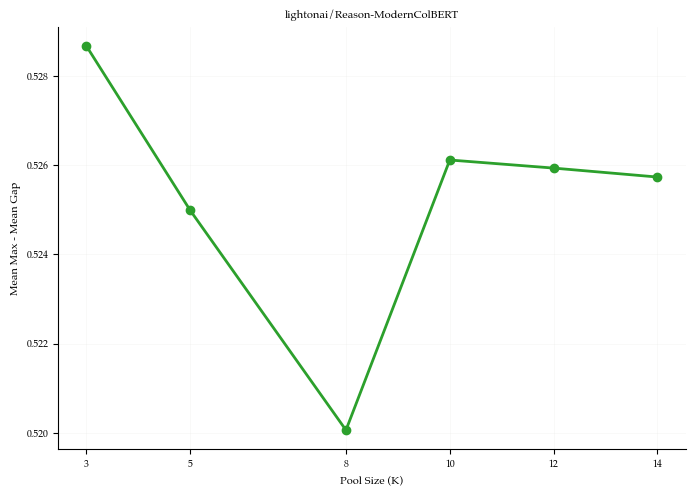

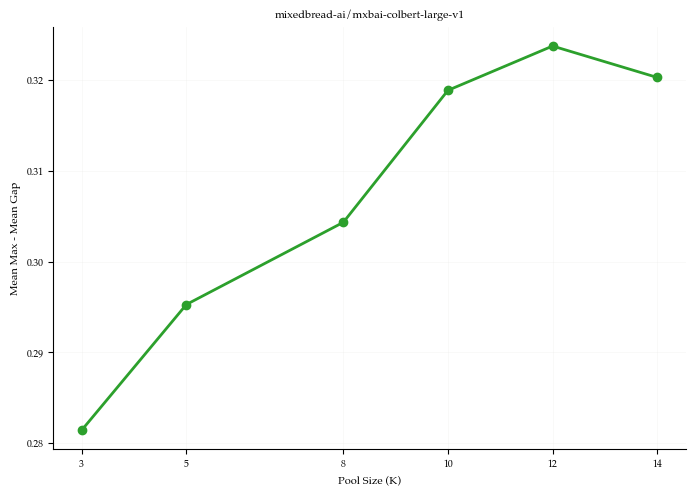

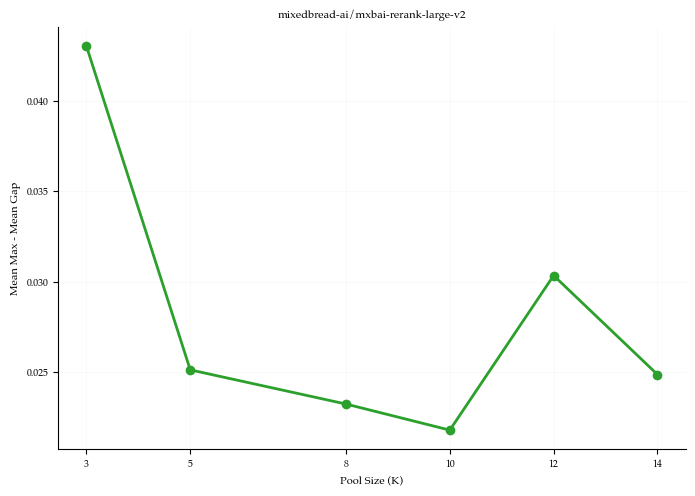

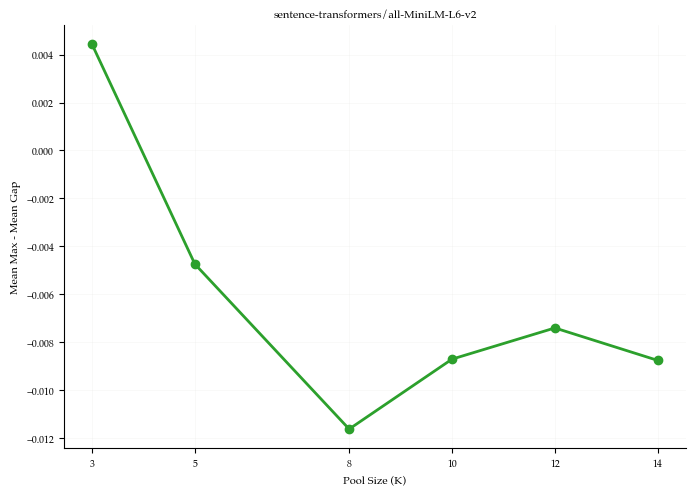

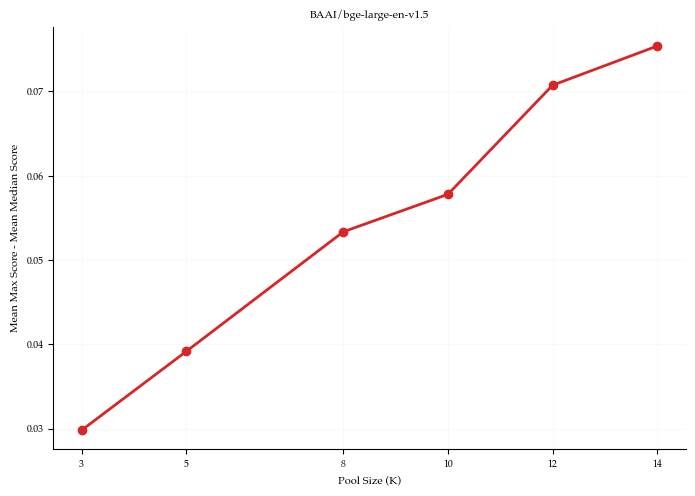

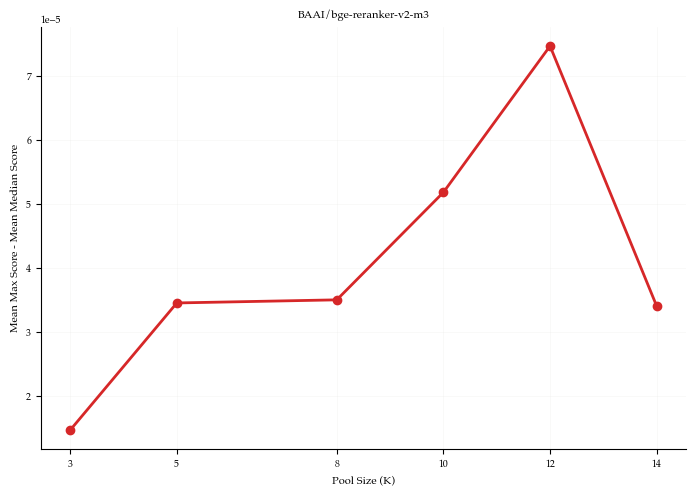

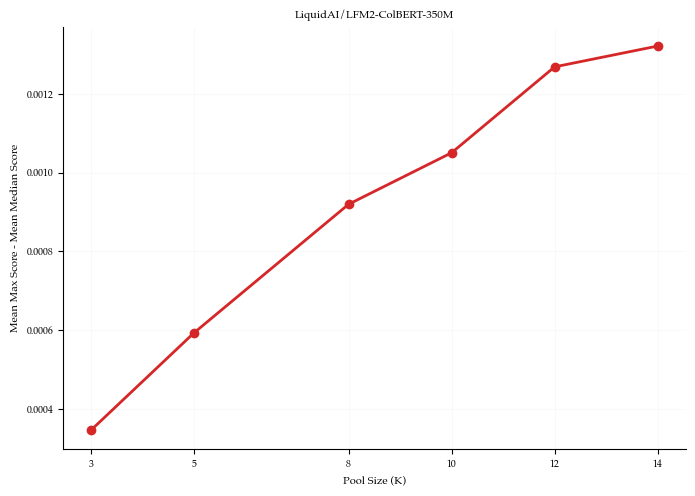

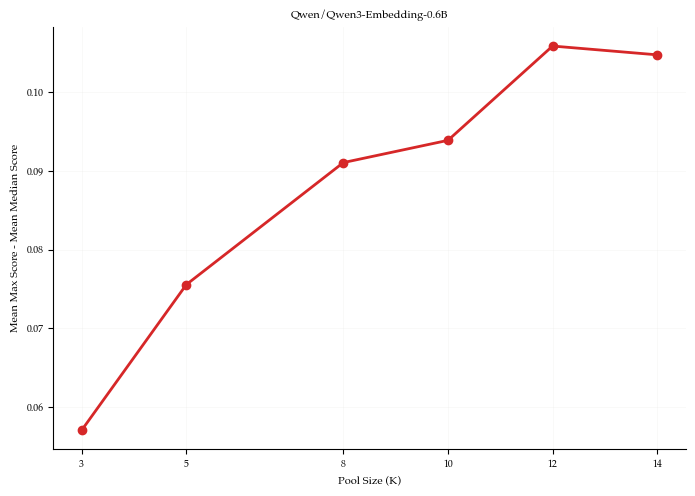

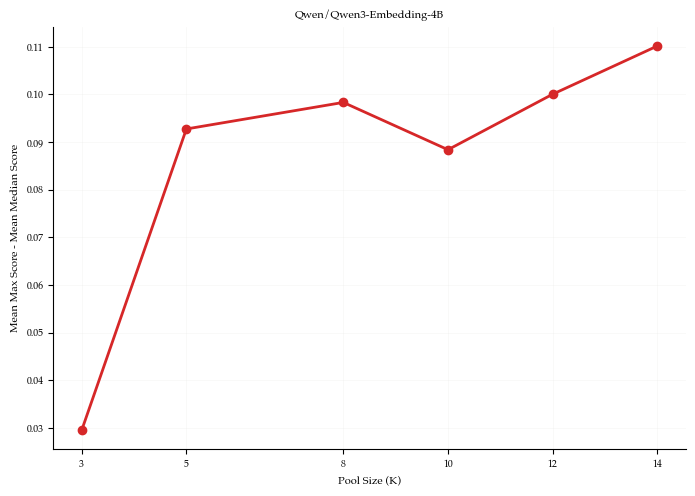

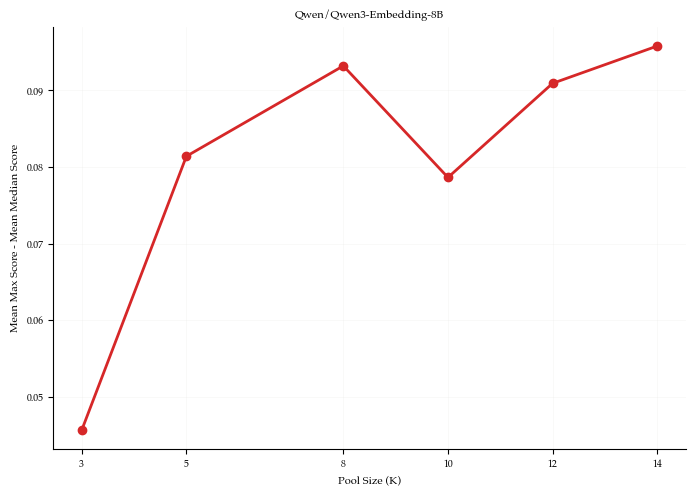

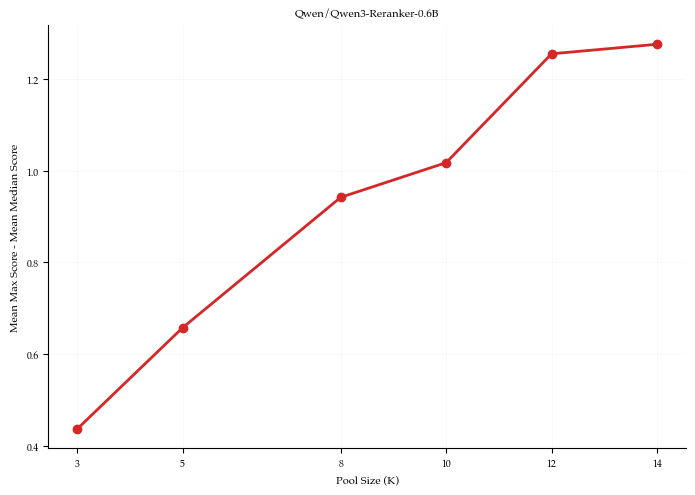

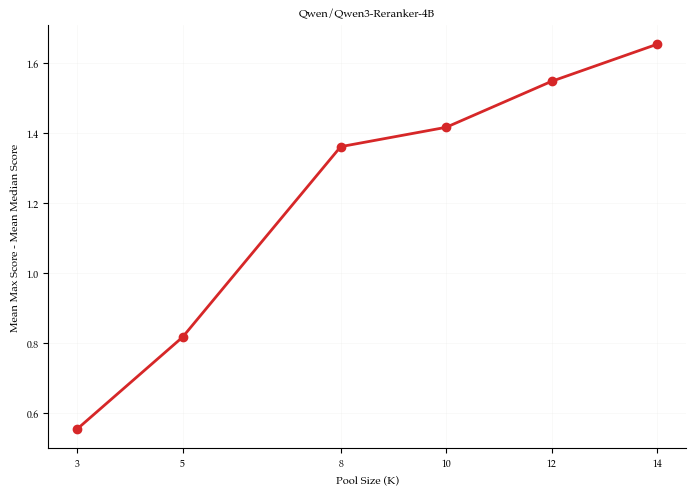

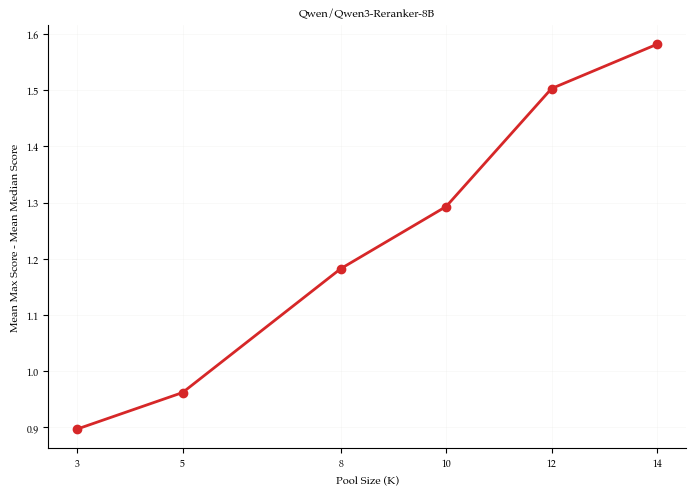

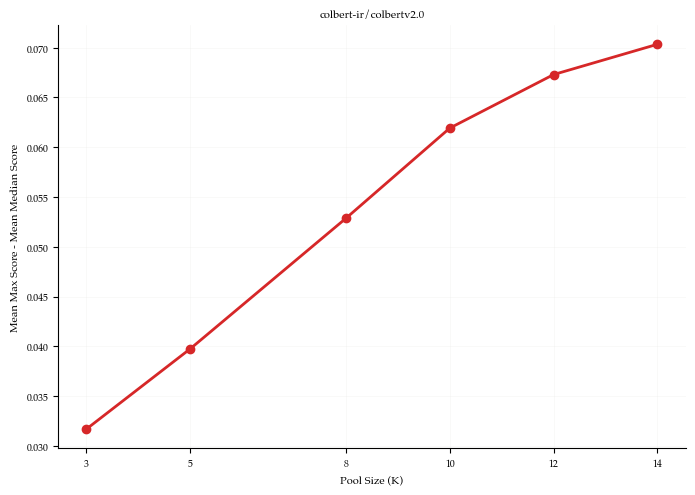

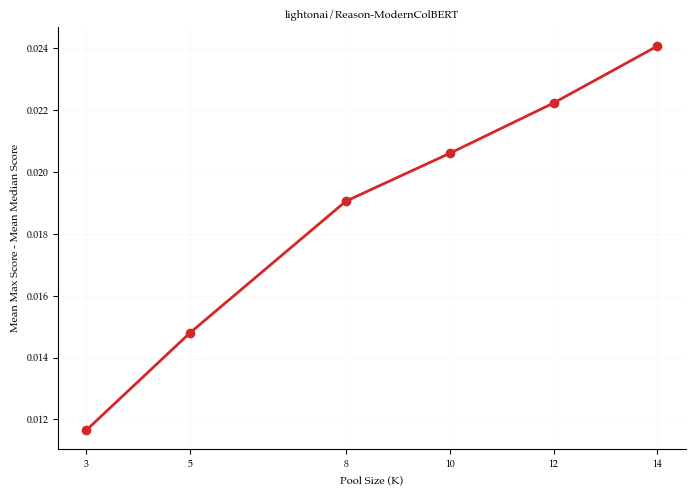

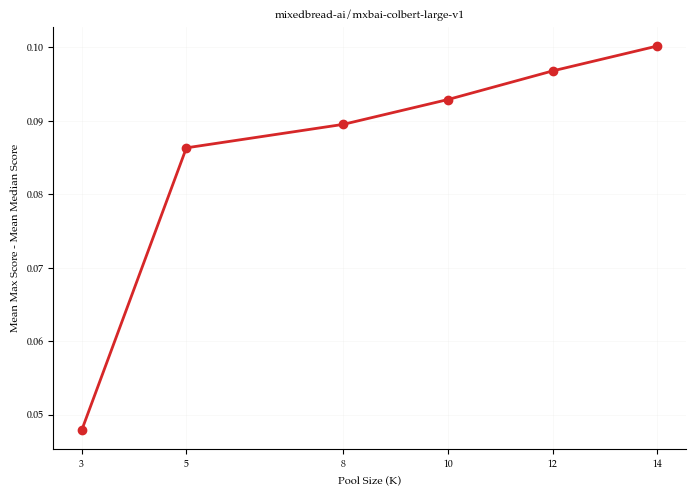

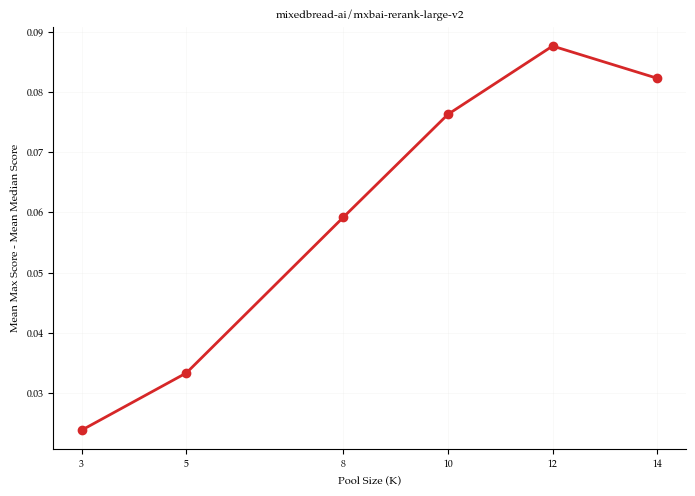

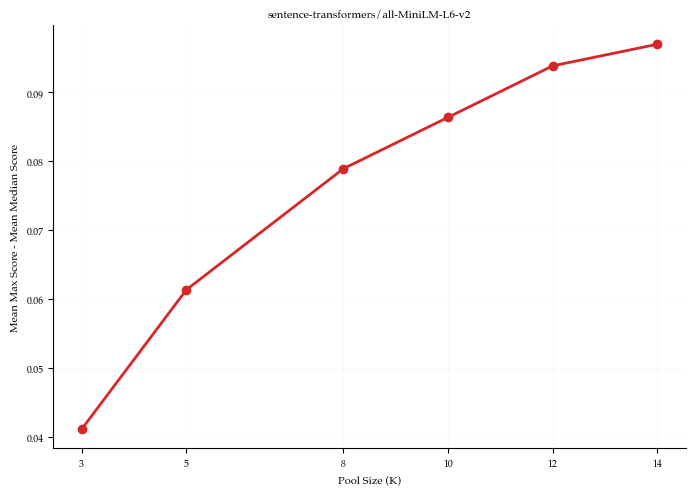

In [57]:
import matplotlib.pyplot as plt

for model, df_model in general_stats.groupby("model_name"):

    plt.figure(figsize=(7, 5))

    plt.plot(
        df_model["total_service_count"],
        df_model["max_minus_median"],
        marker="o",
        linewidth=2,
        color="tab:red"
    )

    plt.xlabel("Pool Size (K)")
    plt.ylabel("Mean Max Score - Mean Median Score")
    plt.title(model)
    plt.xticks(df_model["total_service_count"])
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

## Ablation k-aware threshold

In [10]:
models = ["BAAI/bge-large-en-v1.5",
          "lightonai/Reason-ModernColBERT",
          "Qwen/Qwen3-Reranker-4B"]

df_k = df_combined[df_combined["model_name"].isin(models)]

keys = ["model_name", "routing_method", "total_service_count"]

acc  = df_k.groupby(keys)["is_correct"].mean() * 100
spec = df_k[df_k["expected_service"] != "general"].groupby(keys)["is_correct"].mean() * 100
gen  = df_k[df_k["expected_service"] == "general"].groupby(keys)["is_correct"].mean() * 100

table = pd.DataFrame({"k-aware Acc": acc,
                      "k-aware Spec": spec,
                      "k-aware Gen": gen}).round(2)
table
# print(table.to_latex(float_format="%.2f"))

k-aware Acc  \
model_name                     routing_method total_service_count                
BAAI/bge-large-en-v1.5         bi-encoder     3                          91.67   
                                              5                          89.00   
                                              8                          82.82   
                                              10                         80.77   
                                              12                         71.27   
                                              14                         69.00   
Qwen/Qwen3-Reranker-4B         cross-encoder  3                          97.50   
                                              5                          95.12   
                                              8                          87.64   
                                              10                         87.15   
                                              12                         82.73   
                                              14                         81.35   
lightonai/Reason-ModernColBERT colbert        3                          91.67   
                                              5                          89.88   
                                              8                          83.55   
                                              10                         80.46   
                                              12                         74.87   
                                              14                         72.35   

                                                                   k-aware Spec  \
model_name                     routing_method total_service_count                 
BAAI/bge-large-en-v1.5         bi-encoder     3                           89.33   
                                              5                           86.80   
                                              8                           80.38   
                                              10                          78.20   
                                              12                          70.75   
                                              14                          68.36   
Qwen/Qwen3-Reranker-4B         cross-encoder  3                           98.33   
                                              5                           96.40   
                                              8                           89.88   
                                              10                          88.40   
                                              12                          83.17   
                                              14                          81.50   
lightonai/Reason-ModernColBERT colbert        3                           94.33   
                                              5                           88.40   
                                              8                           79.75   
                                              10                          76.30   
                                              12                          70.17   
                                              14                          67.79   

                                                                   k-aware Gen  
model_name                     routing_method total_service_count               
BAAI/bge-large-en-v1.5         bi-encoder     3                          94.00  
                                              5                          92.67  
                                              8                          89.33  
                                              10                         89.33  
                                              12                         73.33  
                                              14                         72.00  
Qwen/Qwen3-Reranker-4B         cross-encoder  3                          96.67  
                                    

In [26]:
gap = df_k[df_k["expected_service"] == "general"].groupby(keys)["gap"].mean()

table = pd.DataFrame({
                      "Off-topic gap": gap}).round(3)
table

Off-topic gap
model_name                     routing_method total_service_count               
BAAI/bge-large-en-v1.5         bi-encoder     3                            0.031
                                              5                            0.038
                                              8                            0.052
                                              10                           0.057
                                              12                           0.070
                                              14                           0.075
Qwen/Qwen3-Reranker-4B         cross-encoder  3                            0.452
                                              5                            0.797
                                              8                            1.273
                                              10                           1.371
                                              12                           1.460
                                              14                           1.569
lightonai/Reason-ModernColBERT colbert        3                            0.012
                                              5                            0.015
                                              8                            0.018
                                              10                           0.020
                                              12                           0.022
                                              14                           0.023

In [11]:
# # Specialist queries only: what happened to each one
# s = df_k[df_k["expected_service"] != "general"].copy()
# s["outcome"] = "confused"                                          # wrong specialist
# s.loc[s["is_correct"], "outcome"] = "correct"                      # right specialist
# s.loc[s["predicted_label"] == "general", "outcome"] = "rejected"   # sent to general

# share = (s.groupby(keys)["outcome"].value_counts(normalize=True)
#           .unstack().mul(100).fillna(0))

# table = pd.DataFrame({"Acc.": acc.round(2), "Spec.": spec.round(2), "Gen.": gen.round(2),
#                       "Rejected": share["rejected"].round(1),
#                       "Confused": share["confused"].round(1),
#                       "Off-topic gap": gap.round(3)})
# table

## Can Retrieval models route?

In [8]:
df_acc = df_combined.copy()     

acc_table = df_acc.pivot_table(
    index=["routing_method", "model_name"],
    columns="total_service_count",
    values="is_correct",
    aggfunc="mean",
).mul(100).round(2)

acc_table = acc_table.sort_values(["routing_method", 14], ascending=[True, False])
# acc_table.to_latex()
acc_table

total_service_count                                       3      5      8   \
routing_method model_name                                                    
bi-encoder     sentence-transformers/all-MiniLM-L6-v2  88.67  78.53  75.58   
               Qwen/Qwen3-Embedding-8B                 87.33  82.13  75.50   
               BAAI/bge-large-en-v1.5                  90.22  89.20  83.00   
               Qwen/Qwen3-Embedding-0.6B               83.78  77.47  72.58   
               Qwen/Qwen3-Embedding-4B                 86.00  72.27  67.33   
colbert        lightonai/Reason-ModernColBERT          93.56  89.87  84.08   
               LiquidAI/LFM2-ColBERT-350M              92.89  84.53  81.33   
               mixedbread-ai/mxbai-colbert-large-v1    77.78  70.80  67.58   
               colbert-ir/colbertv2.0                  69.33  64.80  60.83   
cross-encoder  Qwen/Qwen3-Reranker-8B                  91.78  94.13  90.33   
               Qwen/Qwen3-Reranker-4B                  96.44  95.33  86.83   
               mixedbread-ai/mxbai-rerank-large-v2     93.78  89.73  85.08   
               Qwen/Qwen3-Reranker-0.6B                91.56  86.40  81.75   
               BAAI/bge-reranker-v2-m3                 92.67  84.00  74.33   

total_service_count                                       10     12     14  
routing_method model_name                                                   
bi-encoder     sentence-transformers/all-MiniLM-L6-v2  75.27  73.17  71.43  
               Qwen/Qwen3-Embedding-8B                 75.40  71.56  69.57  
               BAAI/bge-large-en-v1.5                  82.00  70.56  68.14  
               Qwen/Qwen3-Embedding-0.6B               72.47  69.00  68.10  
               Qwen/Qwen3-Embedding-4B                 69.13  64.11  62.81  
colbert        lightonai/Reason-ModernColBERT          82.27  77.94  76.10  
               LiquidAI/LFM2-ColBERT-350M              78.60  72.89  71.52  
               mixedbread-ai/mxbai-colbert-large-v1    65.47  63.50  61.95  
               colbert-ir/colbertv2.0                  60.80  59.11  56.76  
cross-encoder  Qwen/Qwen3-Reranker-8B                  90.07  85.11  83.48  
               Qwen/Qwen3-Reranker-4B                  85.53  81.22  79.05  
               mixedbread-ai/mxbai-rerank-large-v2     83.53  79.50  78.57  
               Qwen/Qwen3-Reranker-0.6B                79.40  74.28  72.71  
               BAAI/bge-reranker-v2-m3                 73.47  70.67  66.76

## How well are specialist and off-topic queries routed?

In [15]:
keys = ["routing_method", "model_name", "total_service_count"]
is_general = df_acc["expected_service"] == "general"

acc  = df_acc.groupby(keys)["is_correct"].mean() * 100
spec = df_acc[~is_general].groupby(keys)["is_correct"].mean() * 100
gen  = df_acc[is_general].groupby(keys)["is_correct"].mean() * 100

df_recall = pd.DataFrame({"Acc.": acc, "Spec.": spec, "Gen.": gen}).round(2)
df_recall

k3_recall  = df_recall.xs(3,  level="total_service_count")
k14_recall = df_recall.xs(14, level="total_service_count")

recall_k3_k14 = pd.concat([k3_recall, k14_recall], axis=1, keys=["K=3", "K=14"])
recall_k3_k14

K=3                \
                                                        Acc.  Spec.   Gen.   
routing_method model_name                                                    
bi-encoder     BAAI/bge-large-en-v1.5                  90.22  89.33  92.00   
               Qwen/Qwen3-Embedding-0.6B               83.78  80.00  91.33   
               Qwen/Qwen3-Embedding-4B                 86.00  80.33  97.33   
               Qwen/Qwen3-Embedding-8B                 87.33  83.67  94.67   
               sentence-transformers/all-MiniLM-L6-v2  88.67  86.67  92.67   
colbert        LiquidAI/LFM2-ColBERT-350M              92.89  92.67  93.33   
               colbert-ir/colbertv2.0                  69.33  60.67  86.67   
               lightonai/Reason-ModernColBERT          93.56  94.33  92.00   
               mixedbread-ai/mxbai-colbert-large-v1    77.78  74.00  85.33   
cross-encoder  BAAI/bge-reranker-v2-m3                 92.67  90.67  96.67   
               Qwen/Qwen3-Reranker-0.6B                91.56  92.00  90.67   
               Qwen/Qwen3-Reranker-4B                  96.44  98.33  92.67   
               Qwen/Qwen3-Reranker-8B                  91.78  97.33  80.67   
               mixedbread-ai/mxbai-rerank-large-v2     93.78  93.67  94.00   

                                                        K=14                
                                                        Acc.  Spec.   Gen.  
routing_method model_name                                                   
bi-encoder     BAAI/bge-large-en-v1.5                  68.14  68.36  67.71  
               Qwen/Qwen3-Embedding-0.6B               68.10  55.64  93.00  
               Qwen/Qwen3-Embedding-4B                 62.81  45.79  96.86  
               Qwen/Qwen3-Embedding-8B                 69.57  55.50  97.71  
               sentence-transformers/all-MiniLM-L6-v2  71.43  62.36  89.57  
colbert        LiquidAI/LFM2-ColBERT-350M              71.52  66.64  81.29  
               colbert-ir/colbertv2.0                  56.76  42.86  84.57  
               lightonai/Reason-ModernColBERT          76.10  67.79  92.71  
               mixedbread-ai/mxbai-colbert-large-v1    61.95  51.21  83.43  
cross-encoder  BAAI/bge-reranker-v2-m3                 66.76  52.36  95.57  
               Qwen/Qwen3-Reranker-0.6B                72.71  67.57  83.00  
               Qwen/Qwen3-Reranker-4B                  79.05  81.50  74.14  
               Qwen/Qwen3-Reranker-8B                  83.48  81.36  87.71  
               mixedbread-ai/mxbai-rerank-large-v2     78.57  70.36  95.00

In [10]:
general = df_combined[df_combined["expected_service"] == "general"]
print(general.shape)


(36400, 42)


In [12]:
general.groupby(["model_name", "total_service_count"])[["max_score", "median_score"]].mean().round(4)

max_score  \
model_name                             total_service_count              
BAAI/bge-large-en-v1.5                 3                       0.3607   
                                       5                       0.3762   
                                       8                       0.3762   
                                       10                      0.3777   
                                       12                      0.3914   
                                       14                      0.3914   
BAAI/bge-reranker-v2-m3                3                       0.0000   
                                       5                       0.0001   
                                       8                       0.0001   
                                       10                      0.0001   
                                       12                      0.0001   
                                       14                      0.0001   
LiquidAI/LFM2-ColBERT-350M             3                       0.9314   
                                       5                       0.9268   
                                       8                       0.9266   
                                       10                      0.9279   
                                       12                      0.9297   
                                       14                      0.9289   
Qwen/Qwen3-Embedding-0.6B              3                       0.2376   
                                       5                       0.2477   
                                       8                       0.2470   
                                       10                      0.2526   
                                       12                      0.2528   
                                       14                      0.2496   
Qwen/Qwen3-Embedding-4B                3                       0.2193   
                                       5                       0.2784   
                                       8                       0.2739   
                                       10                      0.2764   
                                       12                      0.2812   
                                       14                      0.2782   
Qwen/Qwen3-Embedding-8B                3                       0.1726   
                                       5                       0.2032   
                                       8                       0.2032   
                                       10                      0.2071   
                                       12                      0.2093   
                                       14                      0.2070   
Qwen/Qwen3-Reranker-0.6B               3                      -9.1406   
                                       5                      -9.1017   
                                       8                      -8.9134   
                                       10                     -8.8768   
                                       12                     -8.5127   
                                       14                     -8.6132   
Qwen/Qwen3-Reranker-4B                 3                     -10.9952   
                                       5                     -10.9076   
                                       8                     -10.5474   
                                       10                    -10.5609   
                                       12                    -10.3513   
                                       14                    -10.4528   
Qwen/Qwen3-Reranker-8B                 3                     -10.8985   
                                       5                     -10.6134   
                                       8                     -10.4673   
                                       10                    -10.4024   
                                       12                     -9.9595   
                                       14    

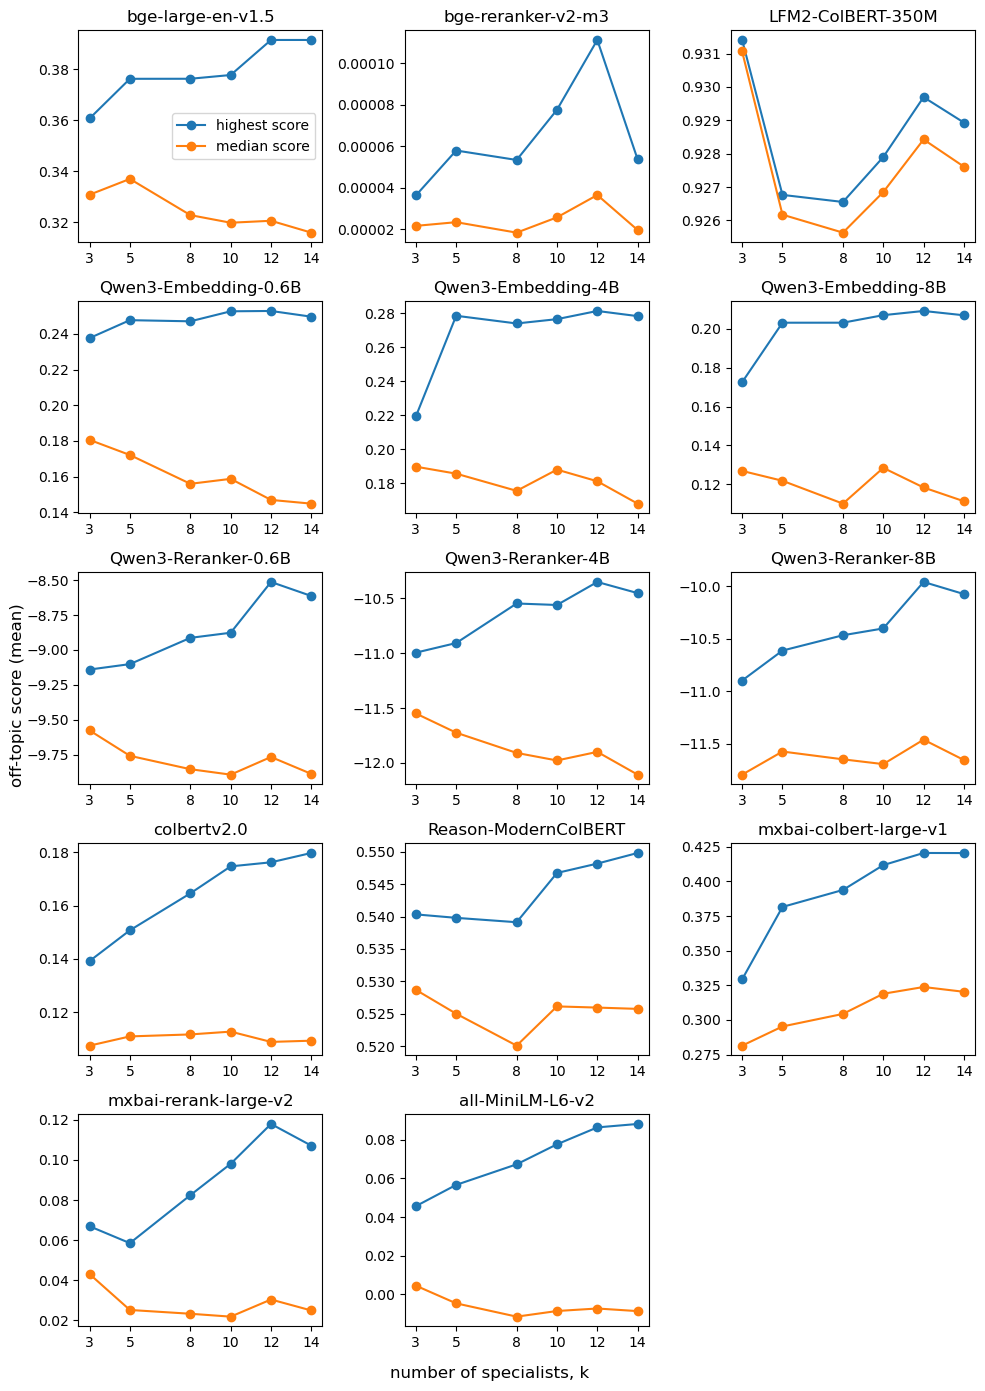

In [16]:
import matplotlib.pyplot as plt

means = general.groupby(["model_name", "total_service_count"])[["max_score", "median_score"]].mean()
models = means.index.get_level_values("model_name").unique()

fig, axes = plt.subplots(5, 3, figsize=(10, 14))

for ax, m in zip(axes.ravel(), models):
    d = means.loc[m]                                  
    ax.plot(d.index, d["max_score"],    "-o", color="tab:blue",   label="highest score")
    ax.plot(d.index, d["median_score"], "-o", color="tab:orange", label="median score")
    ax.set_title(m.split("/")[-1])
    ax.set_xticks(d.index)

for ax in axes.ravel()[len(models):]:                  
    ax.axis("off")

axes[0, 0].legend()
fig.supxlabel("number of specialists, k")
fig.supylabel("off-topic score (mean)")
plt.tight_layout()
plt.show()

fig.savefig("median_vs_max_general_growing.png", dpi=300, bbox_inches="tight") 


In [24]:
p90_test = (general.groupby(["model_name", "total_service_count"])["gap"]
                   .quantile(0.9)
                   .unstack())

pd.set_option("display.float_format", "{:.8f}".format)    # show 8 decimals
p90_test

total_service_count,3,5,8,10,12,14
model_name,,,,,,
BAAI/bge-large-en-v1.5,0.06067519,0.06203768,0.08058486,0.08139661,0.10459933,0.10888942
BAAI/bge-reranker-v2-m3,0.00001447,0.00000480,0.00000911,0.00002892,0.00003452,0.00003868
LiquidAI/LFM2-ColBERT-350M,0.00061555,0.00135832,0.00197181,0.00181654,0.00234177,0.00234460
Qwen/Qwen3-Embedding-0.6B,0.10323289,0.12259496,0.13321199,0.12816056,0.14185749,0.14081889
Qwen/Qwen3-Embedding-4B,0.05915714,0.12362565,0.12762937,0.11694656,0.12914561,0.13734761
Qwen/Qwen3-Embedding-8B,0.07809035,0.10921454,0.12198335,0.10501126,0.11711037,0.12071919
Qwen/Qwen3-Reranker-0.6B,1.06875000,1.37500000,1.78750000,1.87500000,2.21875000,2.34375000
Qwen/Qwen3-Reranker-4B,1.06250000,1.50000000,2.28125000,2.35000000,2.59687500,2.69062500
Qwen/Qwen3-Reranker-8B,1.50625000,1.63125000,1.93750000,2.00000000,2.31250000,2.40625000


In [35]:
# import numpy as np

# y = p90_test.loc["BAAI/bge-large-en-v1.5"].values
# print(y)

# K = np.array(p90_test.columns, dtype=float)
# print(K)

# x = np.log(K)

# c1, c0 = np.polyfit(x, y, 1)
# print(c0, c1)

# fit = c0 + c1 * x

# r2 = 1 - ((y - fit) ** 2).sum() / ((y - y.mean()) ** 2).sum()
# print(r2)

In [33]:
K = np.array(p90_test.columns, dtype=float)      
x = np.log(K)

rows = []
for m in p90_test.index:
    y = p90_test.loc[m].values
    c1, c0 = np.polyfit(x, y, 1)                  
    fit = c0 + c1 * x
    r2 = 1 - ((y - fit) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    rows.append(dict(model=m, c0=c0, c1=c1, R2=r2))

fit_test = pd.DataFrame(rows).set_index("model")
fit_test

,c0,c1,R2
model,,,
BAAI/bge-large-en-v1.5,0.01754899,0.03216701,0.84386465
BAAI/bge-reranker-v2-m3,-0.00001583,0.00001846,0.57819532
LiquidAI/LFM2-ColBERT-350M,-0.00051386,0.00110788,0.94894419
Qwen/Qwen3-Embedding-0.6B,0.08068869,0.02339477,0.90658747
Qwen/Qwen3-Embedding-4B,0.03228485,0.04094819,0.70277816
Qwen/Qwen3-Embedding-8B,0.06184538,0.02301096,0.67005287
Qwen/Qwen3-Reranker-0.6B,0.09804322,0.82531988,0.97297979
Qwen/Qwen3-Reranker-4B,-0.17522041,1.10795212,0.98129322
Qwen/Qwen3-Reranker-8B,0.76418144,0.59019463,0.92564307


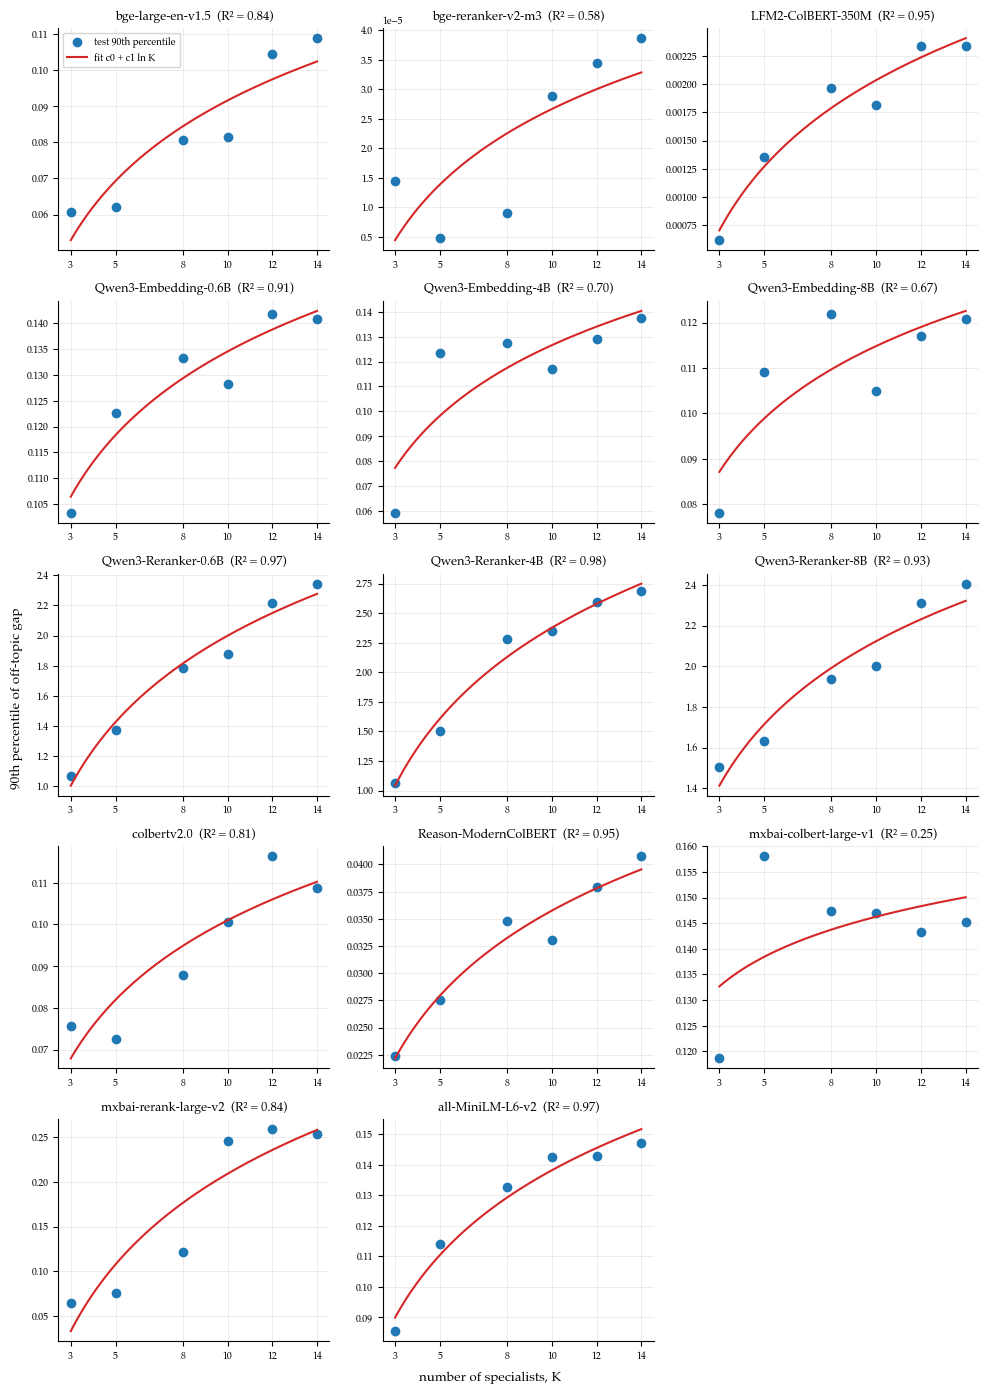

In [34]:
K = np.array(p90_test.columns, dtype=float)
k_line = np.linspace(3, 14, 100)          

fig, axes = plt.subplots(5, 3, figsize=(10, 14))

for ax, m in zip(axes.ravel(), p90_test.index):
    c0 = fit_test.loc[m, "c0"]
    c1 = fit_test.loc[m, "c1"]
    r2 = fit_test.loc[m, "R2"]

    ax.plot(K, p90_test.loc[m].values, "o", color="tab:blue", label="test 90th percentile")
    ax.plot(k_line, c0 + c1 * np.log(k_line), "-", color="tab:red", label="fit c0 + c1 ln K")

    ax.set_title(f"{m.split('/')[-1]}  (R² = {r2:.2f})", fontsize=9)
    ax.set_xticks(K)

for ax in axes.ravel()[len(p90_test.index):]:
    ax.axis("off")

axes[0, 0].legend(fontsize=7)
fig.supxlabel("number of specialists, K")
fig.supylabel("90th percentile of off-topic gap")
plt.tight_layout()

fig.savefig("test_fit_log.png", dpi=300, bbox_inches="tight")   # save before show
plt.show()